# 1.1 — RQ0b: Is there a structural break in how US population growth responds to income?

For each decade d: Δln(pop)_{i,d} = α_d + β_d · ln(income per capita)_{i,d}.
States 1880–2020 (Klein, Easterlin, BEA); metros 1940–2020 (IPUMS 1940 wages, Census medians, BEA).
Break tests pool all decades with decade fixed effects (see Claude/methods/analysis-methods.md).
Findings are descriptive and associational.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from us_housing_crisis_analysis.config import PROCESSED_DATA_DIR, RQ0B_METRO_START, RQ0B_STATE_START, TABLES_DIR
from us_housing_crisis_analysis.modeling import breaks
from us_housing_crisis_analysis.plots import MUTED, SERIES_MARKERS, TEXT, apply_style, save_figure

apply_style()
metro_panel = pd.read_parquet(PROCESSED_DATA_DIR / "us_metro_longrun.parquet")
panels = {
    "states": breaks.prepare_decade_panel(pd.read_parquet(PROCESSED_DATA_DIR / "us_state_longrun.parquet"), RQ0B_STATE_START),
    "metros": breaks.prepare_decade_panel(metro_panel, RQ0B_METRO_START),
}
# Robustness: 1940 metro income with missing wages left out of the denominator (not counted as 0)
metros_wages_reported = breaks.prepare_decade_panel(
    metro_panel.assign(income_pc=metro_panel.income_pc_wages_reported), RQ0B_METRO_START)
{k: (v.decade.min(), v.decade.max(), v.geo_id.nunique(), len(v)) for k, v in panels.items()}

2026-10-14 21:34:55.468 | INFO     | us_housing_crisis_analysis.config:<module>:11 - PROJ_ROOT path is: /Users/lrubin/Documents/code/US Housing Crisis Analysis


{'states': (np.int64(1880), np.int64(2010), 51, 691),
 'metros': (np.int64(1940), np.int64(2010), 386, 3070)}

## β_d by decade

decade    beta      se    n
version                                
states  0     1880  0.1828  0.1096   45
        1     1890  0.0913  0.0465   47
        2     1900  0.1406  0.0552   48
        3     1910  0.0832  0.0404   48
        4     1920  0.0852  0.0472   48
        5     1930  0.0308  0.0295   49
        6     1940  0.1328  0.0322   49
        7     1950  0.2756  0.0850   51
        8     1960  0.2252  0.0727   51
        9     1970 -0.0581  0.1188   51
        10    1980  0.2106  0.1015   51
        11    1990 -0.0794  0.0759   51
        12    2000 -0.0434  0.0449   51
        13    2010 -0.0092  0.0492   51
metros  0     1940  0.0835  0.0312  380
        1     1950  0.0401  0.0444  382
        2     1960  0.0464  0.0359  383
        3     1970 -0.1325  0.0555  386
        4     1980  0.0449  0.0482  384
        5     1990 -0.0723  0.0393  386
        6     2000 -0.0719  0.0290  383
        7     2010  0.0513  0.0214  386

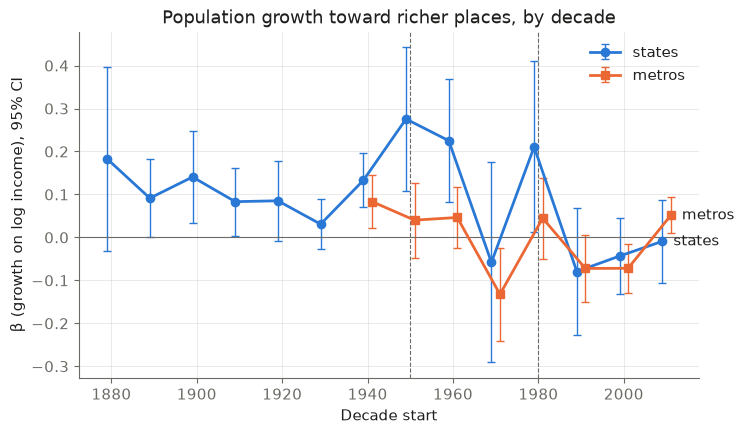

In [2]:
betas = {k: breaks.decade_betas(v) for k, v in panels.items()}
fig, ax = plt.subplots()
for (name, b), offset, marker in zip(betas.items(), (-1, 1), SERIES_MARKERS):
    line = ax.errorbar(b.decade + offset, b.beta, yerr=1.96 * b.se, marker=marker, capsize=3,
                       elinewidth=1, label=name)
    last = b.iloc[-1]
    ax.annotate(name, (last.decade + offset, last.beta), xytext=(8, 0), textcoords="offset points",
                va="center", color=TEXT)
ax.axhline(0, color=MUTED, lw=0.8)
for d in (1950, 1980):
    ax.axvline(d, color=MUTED, ls="--", lw=0.8)
ax.set(xlabel="Decade start", ylabel="β (growth on log income), 95% CI",
       title="Population growth toward richer places, by decade")
ax.legend(loc="upper right")
save_figure(fig, "rq0b_betas")
pd.concat(betas, names=["version"]).round(4)

## Break tests: main specification and robustness

In [3]:
rows = []
for name, dp in panels.items():
    specs = {
        "main": dp,
        "standardized income": breaks.standardize_within_decade(dp),
        "drop source-change decades": dp[~dp.decade.isin(breaks.source_change_decades(dp))],
    }
    if name == "metros":
        specs["1940 missing wages excluded"] = metros_wages_reported
    for spec, d in specs.items():
        for year in (1950, 1980):
            if d.decade.min() < year <= d.decade.max():
                r = breaks.chow_test(d, year)
                rows.append({"version": name, "spec": spec, "test": f"chow_{year}",
                             "statistic": r.statistic, "p_value": r.p_value, "breaks": ""})
        s = breaks.break_search(d)
        rows.append({"version": name, "spec": spec, "test": "break_search_bic",
                     "statistic": s.bic[s.breaks], "p_value": float("nan"),
                     "breaks": " ".join(map(str, s.breaks))})
tests = pd.DataFrame(rows)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
tests.to_csv(TABLES_DIR / "rq0b_tests.csv", index=False)
tests.round(4)

,version,spec,test,statistic,p_value,breaks
0,states,main,chow_1950,0.0014,0.9697,
1,states,main,chow_1980,2.8164,0.0933,
2,states,main,break_search_bic,-2660.8739,NaN,
3,states,standardized income,chow_1950,2.1345,0.1440,
4,states,standardized income,chow_1980,13.5323,0.0002,
5,states,standardized income,break_search_bic,-2652.4224,NaN,1970
6,states,drop source-change decades,chow_1950,0.0247,0.8751,
7,states,drop source-change decades,chow_1980,3.4496,0.0633,
8,states,drop source-change decades,break_search_bic,-2235.1646,NaN,
9,metros,main,chow_1950,6.5244,0.0106,


## Sanity check against Ganong & Shoag (2017)

Ganong & Shoag find that population flowed toward high-income states from 1880 until about
1980, and that this weakened afterwards. The state-level β_d above should show the same
pattern (positive and fairly stable before 1980, lower after). If it does not, check the
pipeline before interpreting the results.

**Finding (run 2026-10-14, after the Plan 1 review fixes):** The sanity check passes. State β_d is positive in every decade from 1880 to 1960 (0.03–0.28) and is zero or negative from 1990 on (−0.08 to −0.01), the direction Ganong & Shoag report; the 1970s (negative) and 1980s (0.21) are noisy. Metro β_d is lower than the state value in 1950–1980 and close to it from 1990 on. The break tests do not pin down the timing: for states, neither Chow test rejects at 5% in the main specification (1950 p = 0.97, 1980 p = 0.09) and the BIC search picks no break, but with income standardized within decade the 1980 Chow test rejects (p < 0.001) and the search picks 1970. For metros, the 1950 Chow test rejects in every specification (p = 0.004–0.03), including with missing 1940 wages left out rather than counted as zero; but the period before 1950 is the 1940 decade alone, the only wage-only decade, so this test can't separate a change in behavior from the change of income concept. The search picks 1970, which is also when the income source switches to BEA; with the source-change decades dropped it picks 1990 and the 1980 Chow test rejects (p = 0.01). Limitations: 1940 metro income is wages only, 1950–60 metro income is a population-weighted mean of county medians, the metro panel starts in 1940, and with 14 (states) or 8 (metros) decades the break search has little power to separate 1970, 1980 and 1990.

## Annual data: when did the break happen? (Plan 1b)

BEA only, every year: states 1929–2024, metros 1969–2024. Two views:
- **Rolling β (the picture):** the decade model on ten-year windows starting every year
  (and five-year windows as a check).
- **Single break (the test):** one-year growth with year fixed effects and a slope that changes
  in year T. sup-Wald (clustered by unit) against Andrews' critical value says whether there is a
  break; T is the best-fitting year; the range comes from resampling units (checked by
  simulation) with Bai's (1997) interval alongside.

One-year slopes are about a tenth of the ten-year β; the ×10 columns put them on the decade scale.

In [4]:
from us_housing_crisis_analysis import features
from us_housing_crisis_analysis.config import (
    ENERGY_STATES_HAND, INTERIM_DATA_DIR, RQ0B_ANNUAL_END, RQ0B_ANNUAL_METRO_START,
    RQ0B_ANNUAL_STATE_START, WWII_GROWTH_YEARS,
)
from us_housing_crisis_analysis.modeling import annual_breaks as ab
from us_housing_crisis_analysis.plots import MUTED, SERIES_COLORS, SERIES_MARKERS

annual = {"states": pd.read_parquet(PROCESSED_DATA_DIR / "us_state_annual.parquet"),
          "metros": pd.read_parquet(PROCESSED_DATA_DIR / "us_metro_annual.parquet")}
energy = features.energy_states(pd.read_parquet(INTERIM_DATA_DIR / "bea.parquet"))
energy_rule = set(energy.loc[energy.energy, "state_fips"])
print("Energy states by the rule:", ", ".join(energy.loc[energy.energy, "state_name"]))
energy.head(12).round(3)

Energy states by the rule: Wyoming, West Virginia, Oklahoma, New Mexico, Louisiana, Kentucky, Texas, Alaska


,state_fips,state_name,mining_share,ratio,energy
0,56,Wyoming,0.242,11.910,True
1,54,West Virginia,0.159,7.826,True
2,40,Oklahoma,0.099,4.853,True
3,35,New Mexico,0.095,4.663,True
4,22,Louisiana,0.082,4.031,True
5,21,Kentucky,0.078,3.827,True
6,48,Texas,0.064,3.125,True
7,02,Alaska,0.061,3.015,True
8,38,North Dakota,0.056,2.736,False
9,49,Utah,0.054,2.642,False


### Rolling β by window start

In [5]:
starts = {"states": RQ0B_ANNUAL_STATE_START, "metros": RQ0B_ANNUAL_METRO_START}
rolling = {(name, h): ab.rolling_betas(p, h, starts[name], RQ0B_ANNUAL_END)
           for name, p in annual.items() for h in (10, 5)}

### Single-break tests: main specification and robustness

In [6]:
def growth(name, start=None):
    return ab.annual_growth_panel(annual[name], start or starts[name], RQ0B_ANNUAL_END)

def growth_without(name, fips):
    return ab.annual_growth_panel(features.drop_states(annual[name], fips), starts[name], RQ0B_ANNUAL_END)

runs = [  # (version, spec, growth panel, trim)
    ("states", "main", growth("states"), 0.15),
    ("states", "without energy states (rule)", growth_without("states", energy_rule), 0.15),
    ("states", "without energy states (hand list)", growth_without("states", set(ENERGY_STATES_HAND)), 0.15),
    ("states", "standardized income", breaks.standardize_within_decade(growth("states"), period="year"), 0.15),
    ("states", "without WWII years", growth("states")[lambda d: ~d.year.isin(WWII_GROWTH_YEARS)], 0.15),
    ("states", "1969-2024 only", growth("states", RQ0B_ANNUAL_METRO_START), 0.15),
    ("states", "1969-2024 only", growth("states", RQ0B_ANNUAL_METRO_START), 0.05),
    ("metros", "main", growth("metros"), 0.15),
    ("metros", "main", growth("metros"), 0.05),
    ("metros", "without energy states (rule)", growth_without("metros", energy_rule), 0.15),
    ("metros", "without energy states (hand list)", growth_without("metros", set(ENERGY_STATES_HAND)), 0.15),
    ("metros", "standardized income", breaks.standardize_within_decade(growth("metros"), period="year"), 0.15),
]

# The bootstrap range is used where its simulated coverage meets the rule; otherwise Bai's interval
coverage = []
for version in ("states", "metros"):
    dp = next(d for v, s, d, tr in runs if v == version and s == "main" and tr == 0.15)
    cov = ab.range_coverage(dp, ab.sup_wald_break(dp))
    coverage.append({"version": version, **cov})
coverage = pd.DataFrame(coverage).set_index("version")
use_bootstrap = coverage.bootstrap >= ab.COVERAGE_MIN

rows = []
for version, spec, dp, trim in runs:
    r = ab.sup_wald_break(dp, trim)
    boot = ab.bootstrap_break_year(dp, trim)
    bai = ab.bai_interval(dp, r)
    multi = ab.demeaned_break_search(dp)
    rows.append({
        "version": version, "spec": spec, "trim": trim, "break_year": r.break_year, "at_edge": r.at_edge,
        "range_low": boot.low, "range_high": boot.high, "bai_low": bai[0], "bai_high": bai[1],
        "reported_range": "bootstrap" if use_bootstrap[version] else "bai",
        "sup_wald": r.sup_wald, "sup_wald_cv5": r.critical_value,
        "beta_before_annual": r.beta_before, "beta_after_annual": r.beta_after,
        "beta_before_10y": 10 * r.beta_before, "beta_after_10y": 10 * r.beta_after,
        "multi_breaks": " ".join(map(str, multi.breaks)), "n_units": r.n_units,
        "years": f"{r.first_year}-{r.last_year}",
    })
annual_tests = pd.DataFrame(rows)
annual_tests.to_csv(TABLES_DIR / "rq0b_annual_tests.csv", index=False)
coverage.to_csv(TABLES_DIR / "rq0b_annual_range_coverage.csv")
display(coverage.round(3))
annual_tests.round(4)

,bootstrap,bai
version,,
states,0.96,0.555
metros,0.98,0.780


,version,spec,trim,break_year,at_edge,range_low,range_high,bai_low,bai_high,reported_range,sup_wald,sup_wald_cv5,beta_before_annual,beta_after_annual,beta_before_10y,beta_after_10y,multi_breaks,n_units,years
0,states,main,0.15,1990,False,1943,1990,1986,1994,bootstrap,17.8259,8.8098,0.0165,-0.0028,0.1654,-0.0282,1940 1955 1990,51,1929-2023
1,states,without energy states (rule),0.15,1970,False,1946,1990,1967,1973,bootstrap,20.3916,8.8098,0.0162,-0.0051,0.1616,-0.0513,1940 1945 1970,43,1929-2023
2,states,without energy states (hand list),0.15,1970,False,1957,1990,1967,1973,bootstrap,22.0520,8.8098,0.0156,-0.0056,0.1557,-0.0557,1940 1945 1970,43,1929-2023
3,states,standardized income,0.15,1970,False,1955,1990,1967,1973,bootstrap,41.4911,8.8098,0.0054,0.0003,0.0543,0.0032,1939 1944 1970,51,1929-2023
4,states,without WWII years,0.15,1990,False,1950,1990,1985,1995,bootstrap,12.1731,8.8098,0.0132,-0.0028,0.1322,-0.0282,1950 1955 1990,51,1929-2023
5,states,1969-2024 only,0.15,1990,False,1980,1991,1984,1996,bootstrap,2.2312,8.8098,0.0109,-0.0028,0.1088,-0.0282,1980 1989,51,1969-2023
6,states,1969-2024 only,0.05,1990,False,1980,1991,1984,1996,bootstrap,4.2022,9.8368,0.0109,-0.0028,0.1088,-0.0282,1980 1989,51,1969-2023
7,metros,main,0.15,1980,False,1978,2010,1977,1983,bootstrap,5.4765,8.8098,-0.0060,0.0035,-0.0601,0.0352,1981 1990 2007,386,1969-2023
8,metros,main,0.05,1980,False,1975,2010,1977,1983,bootstrap,5.4765,9.8368,-0.0060,0.0035,-0.0601,0.0352,1981 1990 2007,386,1969-2023
9,metros,without energy states (rule),0.15,2009,False,1977,2009,2003,2015,bootstrap,2.9858,8.8098,-0.0020,0.0049,-0.0197,0.0491,1980 1990 2007,325,1969-2023


### Where the state break-year estimates fall

Shares of the bootstrap draws at the most common years, and the Wald statistic at 1970 and at its peak for the no-energy specifications (the best-fit year and the largest Wald can differ).

In [7]:
spec_runs = {(v, s, tr): d for v, s, d, tr in runs}
for spec in ("main", "without energy states (rule)", "without energy states (hand list)"):
    dp = spec_runs[("states", spec, 0.15)]
    shares = pd.Series(ab.bootstrap_break_year(dp, 0.15).estimates).value_counts(normalize=True)
    print(f"states, {spec}: bootstrap shares", shares.head(4).round(3).to_dict())
    if spec != "main":
        r = ab.sup_wald_break(dp, 0.15)
        wald = {y: ab.wald_statistic(dp, y) for y in range(r.first_candidate, r.last_candidate + 1)}
        peak = max(wald, key=wald.get)
        print(f"    Wald at 1970 = {wald[1970]:.1f}; largest Wald = {wald[peak]:.1f} at {peak}")

states, main: bootstrap shares {1990: 0.365, 1970: 0.301, 1989: 0.102, 1943: 0.077}
states, without energy states (rule): bootstrap shares {1970: 0.525, 1990: 0.197, 1967: 0.089, 1971: 0.037}
    Wald at 1970 = 16.5; largest Wald = 20.4 at 1989


states, without energy states (hand list): bootstrap shares {1970: 0.516, 1990: 0.207, 1967: 0.09, 1965: 0.044}
    Wald at 1970 = 17.5; largest Wald = 22.1 at 1989


### Figure: rolling β with the estimated break and its range

PosixPath('/Users/lrubin/Documents/code/US Housing Crisis Analysis/reports/figures/rq0b_annual_betas.png')

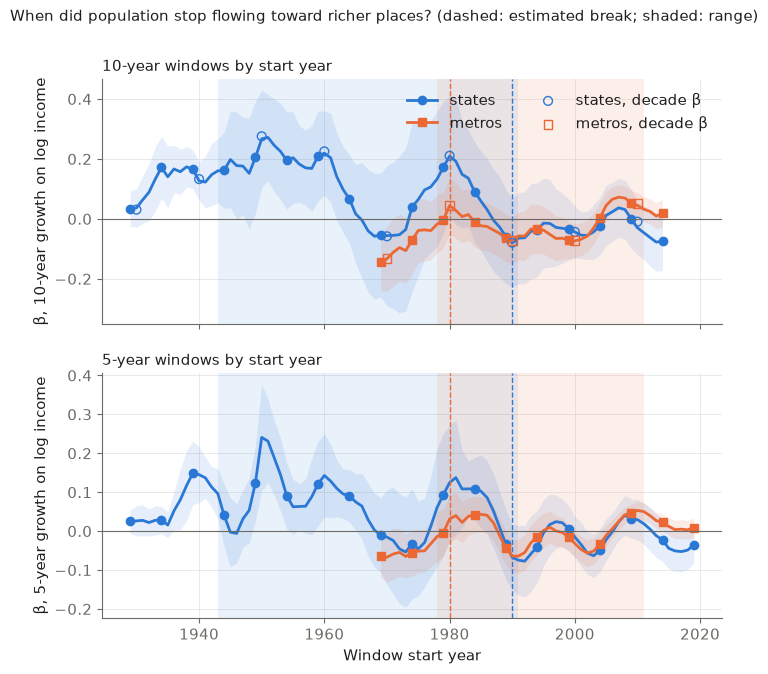

In [8]:
main = annual_tests[(annual_tests.spec == "main") & (annual_tests.trim == 0.15)].set_index("version")
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for ax, h in zip(axes, (10, 5)):
    for i, name in enumerate(("states", "metros")):
        b, color = rolling[(name, h)], SERIES_COLORS[i]
        ax.plot(b.start, b.beta, color=color, marker=SERIES_MARKERS[i], markevery=5, label=name)
        ax.fill_between(b.start, b.beta - 1.96 * b.se, b.beta + 1.96 * b.se, color=color, alpha=0.12, lw=0)
        m = main.loc[name]
        lo, hi = (m.range_low, m.range_high) if m.reported_range == "bootstrap" else (m.bai_low, m.bai_high)
        ax.axvspan(lo, hi + 1, color=color, alpha=0.10, lw=0)
        ax.axvline(m.break_year, color=color, ls="--", lw=1)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(ylabel=f"β, {h}-year growth on log income")
    ax.set_title(f"{h}-year windows by start year", loc="left", fontsize=11)
for i, (name, b) in enumerate(betas.items()):  # decade β from Plan 1, ten-year panel only
    b = b[b.decade >= starts[name]]
    axes[0].scatter(b.decade, b.beta, edgecolors=SERIES_COLORS[i], marker=SERIES_MARKERS[i], s=40,
                    facecolors="none", zorder=3, label=f"{name}, decade β")
axes[0].legend(ncols=2)
axes[1].set(xlabel="Window start year")
fig.suptitle("When did population stop flowing toward richer places? (dashed: estimated break; shaded: range)",
             x=0.01, ha="left", fontsize=11)
save_figure(fig, "rq0b_annual_betas")

**Annual finding (run 2026-10-14):** **The state data show a clear break, but annual data can't pin down the year: the best fit is either about 1970 or about 1990.** Which one wins depends on the specification. With all states and raw income it is 1990. Without the energy states, or with income standardized within year (energy states included), it is 1970. The metro data, and the state data from 1969 on, find no clear single break, but those samples can't test a break before 1977 (1971 with 5% trimming).

- **Is there a break? States 1929–2024: yes.** The test statistic (sup-Wald) is 17.8, against 8.8 needed at the 5% level. On the ten-year scale, β falls from about +0.17 before the break to about −0.03 after.
- **When? States, all states:** the best fit is 1990. But when states are resampled, 37% of the draws pick 1990 and 30% pick 1970 (cell above). The 90% range runs from 1943 or earlier (1943 is the first year the test can name) to 1990. Bai's interval (1986–1994) looks much tighter, but in simulations it held the true year only 56% of the time, so it isn't used.
- **Without the energy states, the best fit moves to 1970.** This holds with both lists: the rule's eight states (Wyoming, West Virginia, Oklahoma, New Mexico, Louisiana, Kentucky, Texas, Alaska) and the hand list. About half the resampling draws pick 1970. The range is still wide (1946–1990 and 1957–1990), and the break is still clear (sup-Wald 20.4 and 22.1). The largest Wald statistic sits at 1989, but the statistic at 1970 is also well above the bar (16.5 and 17.5). β goes from about +0.16 to about −0.05.
- **Standardized income moves it to 1970 too.** With income standardized within year, and the energy states included, the best fit is also 1970 (range 1955–1990), with the strongest test statistic of all (sup-Wald 41.5). Without the WWII years, it is 1990 (range 1950–1990, sup-Wald 12.2).
- **States 1969–2024 and metros 1969–2024: no clear single break.** sup-Wald is 2.2 for states (4.2 with 5% trimming, which needs 9.8) and 5.5 for metros (needs 8.8, or 9.8 with 5% trimming). These samples can only place a break in 1977 or later (1971 or later with 5% trimming), so they can't speak to a break around 1970. The metros' best-fitting year, 1980, even has β going the other way (−0.06 to +0.04), so it shouldn't be read as a break year. In the picture, β for states rises again for windows starting around 1980 before falling. A single before/after split can't capture that within these years.
- **Several breaks allowed:** the search picks 1940, 1955 and 1990 for all states, and 1940, 1945 and 1970 without the energy states. The 1940s breaks fall in the war and early postwar years, and the 1955 break is a further shift in the 1950s. For metros it picks 1981, 1990 and 2007. Every 1929–2024 state version's later break is about 1970 or about 1990, the same two candidates.
- **How much to trust the ranges:** in simulations, the resampling range held the true year 96% of the time for states and 98% for metros. The metro figure is above the 97% target, so the metro range is on the wide side (conservative). The simulations and the resampling both treat states (or metros) as independent of one another. Shocks that hit a whole region at once would make the true uncertainty larger than these ranges show. No point estimate falls on the first candidate year, so no "at or before" applies to the break years themselves.

**For the paper:** "Annual BEA data confirm that population stopped flowing toward richer states (the ten-year β fell from about +0.17 to about −0.03), but they can't pin down the year. The best fit is about 1990 with all states and raw income, and about 1970 without the energy states or with income standardized within year. The 90% range runs from 1943 or earlier to 1990. From 1969 on, neither states nor metros show a clear single break after 1977, the earliest year those samples can test."